# 1. Merge, deduplication and rule-based screening

First notebook of the pipeline (sections 3.1 and 3.2 of the paper). It turns the two database exports into the set of records classified by the LLM in `02_Classification.ipynb`.

| Part | What it does | Outputs (`data/articles/`) |
|---|---|---|
| 1. Merge and deduplication | Reads the Scopus and Web of Science exports, puts them in one schema, removes duplicates, records without abstract and retracted publications | `all_articles.csv`, `all_articles_meta.csv`, `collection_flow.csv`, `duplicates_log.csv` |
| 2. Rule-based screening | Applies criteria E1–E3 (module `mdm/screening.py`) to title, abstract and author keywords | `screened_articles.csv`, `screening_log.csv`, `screening_validation_sample.csv`, `figures/Fig_A1_PRISMA_2020.*` |

**Inputs** (raw exports, not modified)
- Scopus, 05/11/2026: `data/articles/scopus/Scopus_V2_2475_registros_completos.csv` (2,475 records)
- Web of Science Core Collection, 06/11/2026: `data/articles/wos/WoS_1699_registros_completos.tsv` (1,699 records, Full Record; "marketing" in quotes to turn off lemmatization)
- Search strings and filters: `data/articles/LOG_coleta_2026-11-05.md` (Table 1 and Table A2 of the paper)

**Flow** (Fig. A1): 4,174 identified → 1,070 duplicates → 3,104 unique → 8 without abstract and 1 retracted removed → 3,095 screened → 1,495 excluded (E1 = 1,285; E2 = 196; E3 = 14) → **1,600 retained**.

## Part 1. Merge and deduplication

**Duplicate rule** (PRISMA 2020, identification): (1) same DOI; (2) same normalized title, year within ±1 and compatible first author, across and within databases. Pairs listed in `MANUAL_KEEP_DISTINCT` are distinct documents kept separate by author decision.

In [1]:
# Imports and configuration
import warnings
warnings.filterwarnings('ignore')
import re
import unicodedata
import pandas as pd

SCOPUS_FILE = 'data/articles/scopus/Scopus_V2_2475_registros_completos.csv'
WOS_FILE = 'data/articles/wos/WoS_1699_registros_completos.tsv'

OUT_ALL = 'data/articles/all_articles.csv'
OUT_META = 'data/articles/all_articles_meta.csv'
OUT_FLOW = 'data/articles/collection_flow.csv'
OUT_DUP = 'data/articles/duplicates_log.csv'

# Cut-off year. None keeps every record up to the collection date (2027 early-access records are only flagged).
YEAR_MAX = None

# Pairs of database IDs that the rule would merge but that are distinct documents (manual decision).
# Business ethics: Practical proposals for organisations (J Bus Ethics 19:143 in 1999 vs 25:169 in 2000; different DOIs, both in WoS).
MANUAL_KEEP_DISTINCT = [
    ('WOS:000079567300001', 'WOS:000085803200006'),
]

flow = []
def log_step(step, n, note=''):
    flow.append({'step': step, 'records': int(n), 'note': note})
    print(f'{step}: {n}' + (f'  ({note})' if note else ''))

### Read Web of Science and Scopus records

In [2]:
# WoS: tab-delimited, QUOTE_NONE because the fields contain unescaped quotes
wos_raw = pd.read_csv(WOS_FILE, sep='\t', quoting=3, dtype=str, encoding='utf-8-sig')
scopus_raw = pd.read_csv(SCOPUS_FILE, dtype=str, encoding='utf-8-sig')
log_step('Scopus records exported', len(scopus_raw))
log_step('WoS records exported', len(wos_raw))

df_scopus = pd.DataFrame({
    'Title': scopus_raw['Title'], 'Authors': scopus_raw['Authors'],
    'Year': pd.to_numeric(scopus_raw['Year'], errors='coerce'), 'DOI': scopus_raw['DOI'],
    'Abstract': scopus_raw['Abstract'], 'Keywords': scopus_raw['Author Keywords'],
    'Publisher': scopus_raw['Publisher'], 'Source': 'scopus',
    'Cited': pd.to_numeric(scopus_raw['Cited by'], errors='coerce'),
    'IndexKeywords': scopus_raw['Index Keywords'],
    'ID': scopus_raw['EID'], 'DocType': scopus_raw['Document Type'],
    'Stage': scopus_raw['Publication Stage'], 'Journal': scopus_raw['Source title'],
})

df_wos = pd.DataFrame({
    'Title': wos_raw['TI'], 'Authors': wos_raw['AU'],
    'Year': pd.to_numeric(wos_raw['PY'], errors='coerce'), 'DOI': wos_raw['DI'],
    'Abstract': wos_raw['AB'], 'Keywords': wos_raw['DE'],
    'Publisher': wos_raw['PU'], 'Source': 'wos',
    'Cited': pd.to_numeric(wos_raw['Z9'], errors='coerce'),   # Times Cited, All Databases
    'IndexKeywords': wos_raw['ID'],                            # Keywords Plus
    'ID': wos_raw['UT'], 'DocType': wos_raw['DT'], 'Journal': wos_raw['SO'],
})
# Stage comes from DT ("Article; Early Access")
df_wos['Stage'] = df_wos['DocType'].fillna('').str.contains('Early Access').map({True: 'Early access', False: 'Final'})
print('Scopus years:', df_scopus['Year'].min(), '-', df_scopus['Year'].max(), '| WoS years:', df_wos['Year'].min(), '-', df_wos['Year'].max())

Scopus records exported: 2475
WoS records exported: 1699
Scopus years: 1973 - 2027 | WoS years: 1990 - 2027


### Identify duplicates

Within each group of duplicates, the version with the **longest abstract** is kept (more information for the screening and the classification); Scopus comes first on ties. Missing fields are filled from the other versions, the author keywords and the database keywords (Index Keywords, Keywords Plus) of all versions are joined, and `AllIDs` keeps every database ID of the group.

In [3]:
NO_ABSTRACT = re.compile(r'^\s*\[?\s*no abstract available\s*\]?\s*$', re.I)
for d in (df_scopus, df_wos):
    d['Abstract'] = d['Abstract'].where(~d['Abstract'].fillna('').str.match(NO_ABSTRACT), None)
    d['Abstract'] = d['Abstract'].where(d['Abstract'].fillna('').str.strip() != '', None)

df_all = pd.concat([df_scopus, df_wos], ignore_index=True)
log_step('Records identified (Scopus + WoS)', len(df_all))

def strip_acc(x):
    return ''.join(c for c in unicodedata.normalize('NFKD', x) if not unicodedata.combining(c))

def norm_doi(x):
    if pd.isna(x): return None
    x = x.strip().lower()
    x = re.sub(r'^(https?://(dx\.)?doi\.org/|doi:)', '', x)
    return x or None

def norm_title(x):
    if pd.isna(x): return None
    return re.sub(r'[^a-z0-9]', '', strip_acc(x).lower()) or None

def surname(authors, db):
    # WoS: "Surname, I; ..."; Scopus: "Surname I.I.; ..."
    if pd.isna(authors): return None
    first = authors.split(';')[0].strip()
    if db == 'wos':
        first = first.split(',')[0]
    else:
        toks = first.split()
        while len(toks) > 1 and re.fullmatch(r'([A-Z]\.?-?)+', toks[-1]):
            toks.pop()
        first = ' '.join(toks)
    s = re.sub(r'[^a-z]', '', strip_acc(first).lower())
    return s or None

def author_compatible(a, b):
    # Equal, missing/anonymous on one side, or one surname contains the other (parsing of compound names)
    if a is None or b is None or 'anonymous' in (a, b): return True
    return a == b or (len(min(a, b, key=len)) >= 4 and (a.endswith(b) or b.endswith(a)))

df_all['doi_key'] = df_all['DOI'].map(norm_doi)
df_all['title_key'] = df_all['Title'].map(norm_title)
df_all['au1'] = [surname(a, s) for a, s in zip(df_all['Authors'], df_all['Source'])]

keep_distinct = {frozenset(p) for p in MANUAL_KEEP_DISTINCT}
parent = list(range(len(df_all)))
def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i
edges = []   # one entry per merge: (record a, record b, rule)
def union(a, b, rule):
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[rb] = ra
        edges.append((a, b, rule))

# Rule 1: same DOI
for _, idx in df_all[df_all['doi_key'].notna()].groupby('doi_key').groups.items():
    idx = list(idx)
    for j in idx[1:]:
        union(idx[0], j, 'DOI')
n_doi = len({find(i) for i in range(len(df_all))})
log_step('After DOI rule', n_doi, f'{len(df_all) - n_doi} duplicates')

# Rule 2: normalized title + year within +-1 + compatible first author
for _, g in df_all[df_all['title_key'].notna()].groupby('title_key'):
    idx = list(g.index)
    for x in range(len(idx)):
        for y in range(x + 1, len(idx)):
            i, j = idx[x], idx[y]
            if find(i) == find(j): continue
            if frozenset((df_all.at[i, 'ID'], df_all.at[j, 'ID'])) in keep_distinct: continue
            if abs(df_all.at[i, 'Year'] - df_all.at[j, 'Year']) > 1: continue
            if not author_compatible(df_all.at[i, 'au1'], df_all.at[j, 'au1']): continue
            union(i, j, 'title+year+author')

df_all['cluster'] = [find(i) for i in range(len(df_all))]
n_clusters = df_all['cluster'].nunique()
in_both = int(df_all.groupby('cluster')['Source'].nunique().eq(2).sum())
log_step('After title + year (+-1) + first-author rule', n_clusters,
         f'{len(df_all) - n_clusters} duplicates removed in total; {in_both} records in both databases')

Records identified (Scopus + WoS): 4174
After DOI rule: 3131  (1043 duplicates)


After title + year (+-1) + first-author rule: 3104  (1070 duplicates removed in total; 1057 records in both databases)


In [4]:
# Log of merges: one row per link that joined two records (len = number of duplicates removed)
rows = [{'record_a_id': df_all.at[a, 'ID'], 'record_a_db': df_all.at[a, 'Source'], 'record_a_year': df_all.at[a, 'Year'],
         'record_b_id': df_all.at[b, 'ID'], 'record_b_db': df_all.at[b, 'Source'], 'record_b_year': df_all.at[b, 'Year'],
         'title': df_all.at[a, 'Title'], 'doi_a': df_all.at[a, 'DOI'], 'doi_b': df_all.at[b, 'DOI'], 'rule': rule}
        for a, b, rule in edges]
dup_log = pd.DataFrame(rows).sort_values(['rule', 'record_a_id'])
dup_log.to_csv(OUT_DUP, index=False)
assert len(dup_log) == len(df_all) - n_clusters
print(dup_log['rule'].value_counts().to_string())

# Pairs with the same title but different DOIs that were NOT merged (review)
t = df_all[df_all['title_key'].notna() & df_all['doi_key'].notna()].groupby('title_key')['cluster'].nunique()
print('Same title kept as distinct records:', int((t > 1).sum()))

rule
DOI                  1043
title+year+author      27
Same title kept as distinct records: 1


In [5]:
# Merge each cluster: preferred record = with abstract, then Scopus before WoS; fill gaps from the duplicate
df_all['abs_len'] = df_all['Abstract'].fillna('').str.len()
df_all['order'] = range(len(df_all))
df_all = df_all.sort_values(['cluster', 'abs_len', 'order'], ascending=[True, False, True])

dbs = df_all.groupby('cluster')['Source'].agg(lambda s: '+'.join(sorted(set(s))))
retracted = df_all.groupby('cluster')['DocType'].agg(lambda s: s.fillna('').str.contains('Retracted').any())
retracted_title = df_all.groupby('cluster')['Title'].agg(lambda s: s.fillna('').str.match(r'^\s*retracted', case=False).any())
all_ids = df_all.groupby('cluster')['ID'].agg(lambda s: ';'.join(s))
index_kw = df_all.groupby('cluster')['IndexKeywords'].agg(lambda s: ' | '.join(v for v in s.dropna() if v.strip()))

def join_keywords(s):
    # author keywords of all versions, without repetitions (case-insensitive), in order of appearance
    seen, out = set(), []
    for v in s.dropna():
        for k in str(v).split(';'):
            k = k.strip()
            if k and k.lower() not in seen:
                seen.add(k.lower()); out.append(k)
    return '; '.join(out) if out else None
author_kw = df_all.groupby('cluster')['Keywords'].agg(join_keywords)
df_all = (df_all.groupby('cluster', sort=False).first()
                .assign(Source=dbs, Retracted=retracted | retracted_title, AllIDs=all_ids, IndexKeywords=index_kw, Keywords=author_kw)
                .reset_index(drop=True))
df_all = df_all.sort_values('Year', ascending=False, kind='stable').reset_index(drop=True)
print(df_all['Source'].value_counts().to_string())
log_step('Unique records', len(df_all), 'in both databases: %d' % (df_all['Source'] == 'scopus+wos').sum())

Source
scopus        1409
scopus+wos    1057
wos            638
Unique records: 3104  (in both databases: 1057)


### Removals before screening

In [6]:
n0 = len(df_all)
df_all = df_all[df_all['Abstract'].notna()].reset_index(drop=True)
log_step('Removed: without abstract', n0 - len(df_all))

n0 = len(df_all)
df_all = df_all[~df_all['Retracted']].reset_index(drop=True)
log_step('Removed: retracted publication', n0 - len(df_all))

if YEAR_MAX is not None:
    n0 = len(df_all)
    df_all = df_all[df_all['Year'].isna() | (df_all['Year'] <= YEAR_MAX)].reset_index(drop=True)
    log_step(f'Removed: year > {YEAR_MAX}', n0 - len(df_all))

df_all['Year'] = df_all['Year'].astype('Int64')
log_step('Records for screening', len(df_all))
print('Years:', df_all['Year'].min(), '-', df_all['Year'].max(), '| records of 2027:', int((df_all['Year'] == 2027).sum()))
print(df_all['Source'].value_counts().to_string())

Removed: without abstract: 8
Removed: retracted publication: 1
Records for screening: 3095
Years: 1973 - 2027 | records of 2027: 7
Source
scopus        1402
scopus+wos    1057
wos            636


### Document types and publication stage (for screening; nothing is removed here)

In [7]:
print(df_all['DocType'].value_counts().to_string())
print()
print(df_all['Stage'].value_counts().to_string())

DocType
Article                       3032
Article; Early Access           30
Article; Book Chapter           19
Article; Proceedings Paper      14

Stage
Final               2921
Article in press     144
Early access          30


### Save all data in .csv

In [8]:
cols = ['Title', 'Authors', 'Year', 'DOI', 'Abstract', 'Keywords', 'Publisher', 'Source', 'Cited']
df_all[cols].to_csv(OUT_ALL, index=False)
df_all[cols + ['ID', 'DocType', 'Stage', 'Journal', 'AllIDs', 'IndexKeywords']].to_csv(OUT_META, index=False)
pd.DataFrame(flow).to_csv(OUT_FLOW, index=False)
print(f'Saved {len(df_all)} records to {OUT_ALL}')
pd.DataFrame(flow)

Saved 3095 records to data/articles/all_articles.csv


,step,records,note
0,Scopus records exported,2475,
1,WoS records exported,1699,
2,Records identified (Scopus + WoS),4174,
3,After DOI rule,3131,1043 duplicates
4,After title + year (+-1) + first-author rule,3104,1070 duplicates removed in total; 1057 records...
5,Unique records,3104,in both databases: 1057
6,Removed: without abstract,8,
7,Removed: retracted publication,1,
8,Records for screening,3095,


## Part 2. Rule-based screening (criteria E1–E3)

A record is retained only if AI, marketing and decision-making each appear in a substantive way; otherwise it is excluded for the first criterion it fails:

- **E1** AI absent or mentioned only in passing;
- **E2** marketing absent or mentioned only in passing;
- **E3** no decision-making context.

The rules are in `mdm/screening.py` (section 3.2 of the paper). The retained records (`screened_articles.csv`) are the only input of the classification.

In [9]:
import pandas as pd
from mdm import screening, prisma, style

META_FILE = 'data/articles/all_articles_meta.csv'
OUT_SCREENED = 'data/articles/screened_articles.csv'
OUT_LOG = 'data/articles/screening_log.csv'
OUT_SAMPLE = 'data/articles/screening_validation_sample.csv'
SAMPLE_SEED = 2026

### Apply the rules

In [10]:
meta = pd.read_csv(META_FILE, dtype=str, keep_default_na=False)
res = screening.screen(meta)
print('Records screened:', len(res))
print(res['screening_decision'].value_counts().to_string())
print()
print(res.loc[res['screening_decision'] == 'excluded', 'screening_detail'].value_counts().sort_index().to_string())

Records screened: 3095
screening_decision
included    1600
excluded    1495

screening_detail
E1a no AI term used in a technical sense                          1157
E1b AI mentioned only once, as background                          128
E2a marketing only in a non-managerial sense                         6
E2b no "marketing" and not enough marketing vocabulary              32
E2c marketing mentioned once in a list of sectors or functions      91
E2d marketing mentioned once without other marketing terms          67
E3 "decision" only as a technical or legal term                     14


### Save the retained records and the screening log

In [11]:
cols = ['Title', 'Authors', 'Year', 'DOI', 'Abstract', 'Keywords', 'Publisher', 'Source', 'Cited',
        'ID', 'DocType', 'Stage', 'Journal', 'AllIDs']
screened = res[res['screening_decision'] == 'included'][cols]
screened.to_csv(OUT_SCREENED, index=False)
log_cols = ['ID', 'AllIDs', 'Source', 'Year', 'Title', 'screening_decision', 'screening_criterion', 'screening_detail',
            'screening_ai_terms', 'screening_n_ai', 'screening_n_marketing', 'screening_n_marketing_terms', 'screening_n_decision']
res[log_cols].to_csv(OUT_LOG, index=False)
print(f'{len(screened)} records saved to {OUT_SCREENED}')
print(screened['Source'].value_counts().to_string())
print('Years:', screened['Year'].astype(int).min(), '-', screened['Year'].astype(int).max())

1600 records saved to data/articles/screened_articles.csv
Source
scopus        736
scopus+wos    588
wos           276
Years: 1983 - 2027


### Examples of excluded records by criterion

In [12]:
pd.set_option('display.max_colwidth', 110)
(res[res['screening_decision'] == 'excluded'].sample(frac=1, random_state=SAMPLE_SEED)
    .groupby('screening_detail').head(3).sort_values('screening_detail')[['screening_detail', 'Title', 'Year']])

,screening_detail,Title,Year
1581,E1a no AI term used in a technical sense,"Communication channels consumption across awareness building, information search and school choice-perspec...",2022
1750,E1a no AI term used in a technical sense,A quantitative investigation on awareness of renewable energy building technology in the United Arab Emirates,2021
1286,E1a no AI term used in a technical sense,Evaluating strategies for promoting retail mobile channel using a hidden Markov model,2023
1052,"E1b AI mentioned only once, as background",Mapping the Landscape of Sustainability in Social Media: A Bibliometric Analysis and Research Trends,2024
1210,"E1b AI mentioned only once, as background",Tourist arrival forecasting using feed search information,2024
151,"E1b AI mentioned only once, as background",Global Research Trends in Impulsive Buying Behavior within E-Commerce: A Bibliometric Analysis,2026
1955,E2a marketing only in a non-managerial sense,A novel method for predicting the budget impact of innovative medicines: validation study for oncolytics,2020
1036,E2a marketing only in a non-managerial sense,An intelligent decision support system for agriculture economy based on fuzzy c-means,2024
1914,E2a marketing only in a non-managerial sense,Role of big data on digital farming,2020
44,"E2b no ""marketing"" and not enough marketing vocabulary",An interpretable machine learning approach for forecasting the occurrence of extreme electricity prices in...,2026


### Blind sample for checking the rules

The authors code each record of this sample as *retain* or *exclude* (column `decision_human`) without seeing the decision of the rules; the agreement is then computed against `screening_log.csv` (see the last cell).

In [13]:
import os
if not os.path.exists(OUT_SAMPLE):
    sample = pd.concat([res[res['screening_decision'] == d].sample(100, random_state=SAMPLE_SEED) for d in ['included', 'excluded']])
    sample = sample.sample(frac=1, random_state=SAMPLE_SEED)[['ID', 'Title', 'Keywords', 'Abstract']]
    sample['decision_human'] = ''
    sample['criterion_human'] = ''
    sample['notes_human'] = ''
    sample.to_csv(OUT_SAMPLE, index=False, encoding='utf-8-sig')
    print(f'{len(sample)} records written to {OUT_SAMPLE}')
else:
    print(f'{OUT_SAMPLE} already exists (not overwritten)')

data/articles/screening_validation_sample.csv already exists (not overwritten)


In [14]:
# Agreement between the rules and the authors (run after filling decision_human with "retain" or "exclude")
from mdm.classify import _kappa
h = pd.read_csv(OUT_SAMPLE, dtype=str, keep_default_na=False)
h = h[h['decision_human'].str.strip() != '']
if len(h):
    d = h.merge(res[['ID', 'screening_decision']], on='ID')
    rule = d['screening_decision'].map({'included': 'retain', 'excluded': 'exclude'})
    po, k = _kappa(rule, d['decision_human'].str.strip().str.lower())
    print(f'n = {len(d)}; agreement = {po:.3f}; Cohen kappa = {k:.3f}')
else:
    print('The validation sample has not been coded yet.')

The validation sample has not been coded yet.


### PRISMA 2020 flow diagram (Fig. A1)

{'scopus': 2475, 'wos': 1699, 'identified': 4174, 'duplicates': 1070, 'no_abstract': 8, 'retracted': 1, 'screened': 3095, 'excluded': 1495, 'E1': 1285, 'E2': 196, 'E3': 14, 'included': 1600}


'figures/Fig_A1_PRISMA_2020.png'

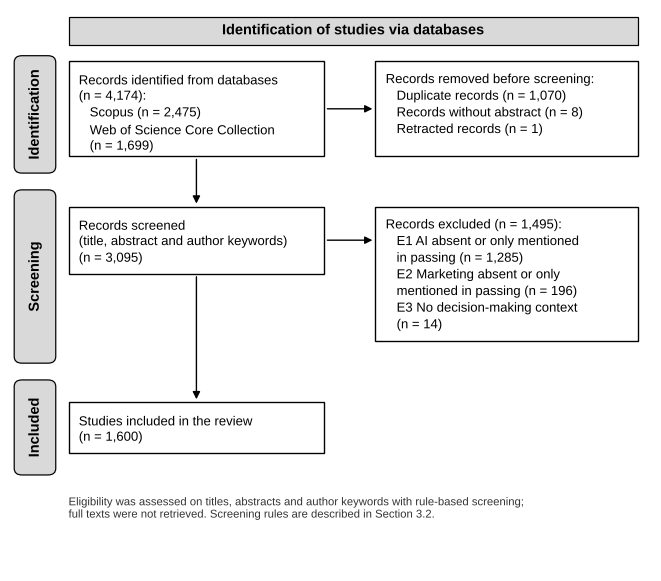

In [15]:
counts = prisma.counts_from_files()
print(counts)
fig = prisma.figure(counts)
style.save(fig, 'Fig_A1_PRISMA_2020')